# Matching Process Trees

### Build graph $G$ and find the connected components (process trees)
1. From the ```process_uber_summary``` table, build an ```igraph``` directed graph $G$ where each edge is of the form: ```parent PID --> child PID```
2. Get all (weak) connected components from $G$ -- those are the ```process trees``` (with one exception where a loop is present, which we drop), and save those in the **Trees** object
    * 99.98% of components are of size 2 (1,111,052  out of 1,111,278) ...
    * 210 process trees contain between 3 and 10k nodes
    * 15 have more then 10k nodes


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from collections import Counter
import igraph as ig
import gzip
import pickle
from functools import partial
from scipy.spatial import distance
import time
import umap 
import random
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay #, precision_score, recall_score,  roc_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import HDBSCAN
import partition_igraph
from sklearn.metrics import adjusted_mutual_info_score as AMI

## our matching algorithm
import sys
import os
sys.path.insert(0,os.path.abspath('../Matching'))
import igraph_io as igio
import fast_match as fm  ## fast version
import needleman_wunsch_tree as nwt ## slower, more flexibility for scoring functions

## several utility functions
from acme_util import *


# Build process trees from the ```process_uber_summary``` table


In [3]:
process_summary = pd.read_parquet("Data/process_uber_summary.parquet", columns=['pid_hash', 'parent_pid_hash', 'process_name', 'user_name', 'red_team'] )
process_summary.head()


,pid_hash,parent_pid_hash,process_name,user_name,red_team
0,A86DB324303BBC24B4C279909AC5AD00,B066C89E8047845304C38E8BEE22AD90,powershell.exe,ACME\user10,1
1,C194ECED319F84EC8DAED02EE44FCE63,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
2,FA50BB30E957D73120420F46B18AE167,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
3,5803C60CEB8387DFA7ADA3E5E75E88FF,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0
4,3BD26DAC90333D99453E9F506A514B1B,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0


In [4]:
## we'll use those throughout
dct_username = dict(zip(process_summary.pid_hash,process_summary.user_name))
dct_label = dict(zip(process_summary.pid_hash,process_summary.red_team))
dct_processname = dict(zip(process_summary.pid_hash,process_summary.process_name))


In [5]:
%%time
Trees = extract_process_trees(process=process_summary, uid='pid_hash', parent_uid='parent_pid_hash',
                              min_tree_size=3, max_tree_size=100000, 
                              extra={'process_name':'process','user_name':'user','red_team':'redteam'})


CPU times: user 14 s, sys: 512 ms, total: 14.6 s
Wall time: 14.6 s


In [6]:
## for plotting - red_team nodes in red
Trees.graph.vs['label_color'] = 'black'
Trees.graph.vs['color'] = 'black'
for v in Trees.graph.vs:
    if dct_label.get(v['uid'],0)>0:
        v['label_color']='red'
        v['color']='red'

# EDA

In [7]:
len(Trees)

224

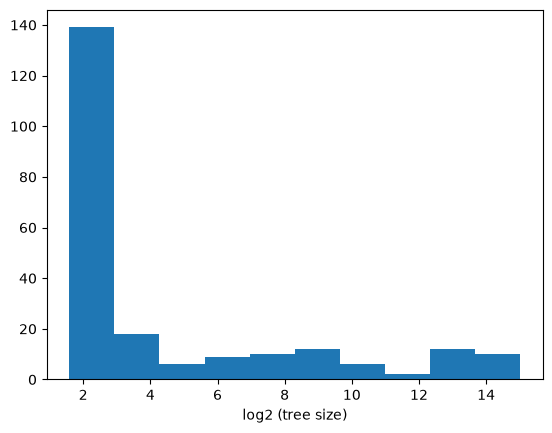

In [8]:
plt.hist([np.log2(x) for x in Trees.sizes()])
plt.xlabel('log2 (tree size)');


In [9]:
Trees.graph.vs[0]

igraph.Vertex(<igraph.Graph object at 0x7aa01d8f9e50>, 0, {'uid': 'B066C89E8047845304C38E8BEE22AD90', 'tree': 0, 'tree_size': 23835, 'process': 'unknown', 'user': None, 'redteam': 1, 'label_color': 'red', 'color': 'red'})

### List all subtrees with known root process name


In [10]:
df_trees = pd.DataFrame()
for t in range(len(Trees)):
    _df = acme_list_process_subtrees(Trees.subgraph(t), dct_username, dct_label)
    _df.insert(loc=0, column='tree', value=t)
    df_trees = pd.concat([df_trees,_df])
df_trees


,tree,root,process,nodes,layers,leaves,bad3,bad9,bad25,redteam
0,0,2,ssm-agent-worker.exe,15904,3,15889,0,0,0,0
1,0,6,svchost.exe,769,3,761,0,0,0,0
2,0,39,ssm-document-worker.exe,4,2,3,0,0,0,0
3,0,52,svchost.exe,24,2,23,0,0,0,0
4,0,56,services.exe,22933,6,21039,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
1,183,4,conhost.exe,4,4,1,0,0,0,0
0,186,0,conhost.exe,3,3,1,0,0,0,0
0,188,2,conhost.exe,3,3,1,0,0,0,0
0,206,1,conhost.exe,3,3,1,0,0,0,0


In [11]:
df_trees[ (df_trees.layers==5) & (df_trees.redteam>0) & (df_trees.nodes==10) ]

,tree,root,process,nodes,layers,leaves,bad3,bad9,bad25,redteam
192,2,12347,notepad++.exe,10,5,5,0,0,0,3
25,27,89,cmd.exe,10,5,6,0,0,0,6


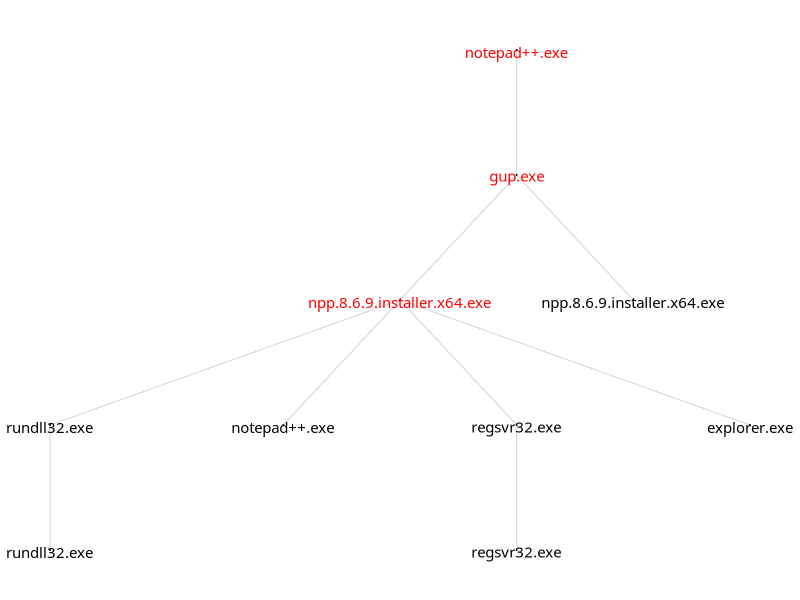

In [12]:
sg = acme_get_bfs_subtree(Trees, 2, 12347)
ig.plot(sg, target="_temp.png", bbox=(800,600), layout=sg.layout_reingold_tilford(), margin=50,
        vertex_size=1,
        vertex_label=sg.vs['process'],
        vertex_label_size=15,
        edge_color='lightgrey', edge_arrow_size=0)    
Image("_temp.png")


# Matching Experiment #1 -  top hits using various weight functions

* we select deep trees with up to 500 nodes (for display purpose)
* we compare "red trees" (with some redteam label) to "black trees"
* (optional) we report matches with at least one redteam label on the red tree matching path

We define different weight functions:

* default: exact match (between process names)
* redblack: exact match but only between redteam and non-readteam
* invfreq: exact match weighted by each process' inverse frequency (log scale)
* embed: exact match weighted by the process' distance in embedded space (built from numerical features)


In [13]:
## extract the subtrees
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=500) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))
Counter(TreeData_label)

Counter({np.False_: 144, np.True_: 32})

### (1a) default weight

This is the default with a binary score of 1 if the process names coincide, 0 otherwise.


In [14]:
## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 8.0


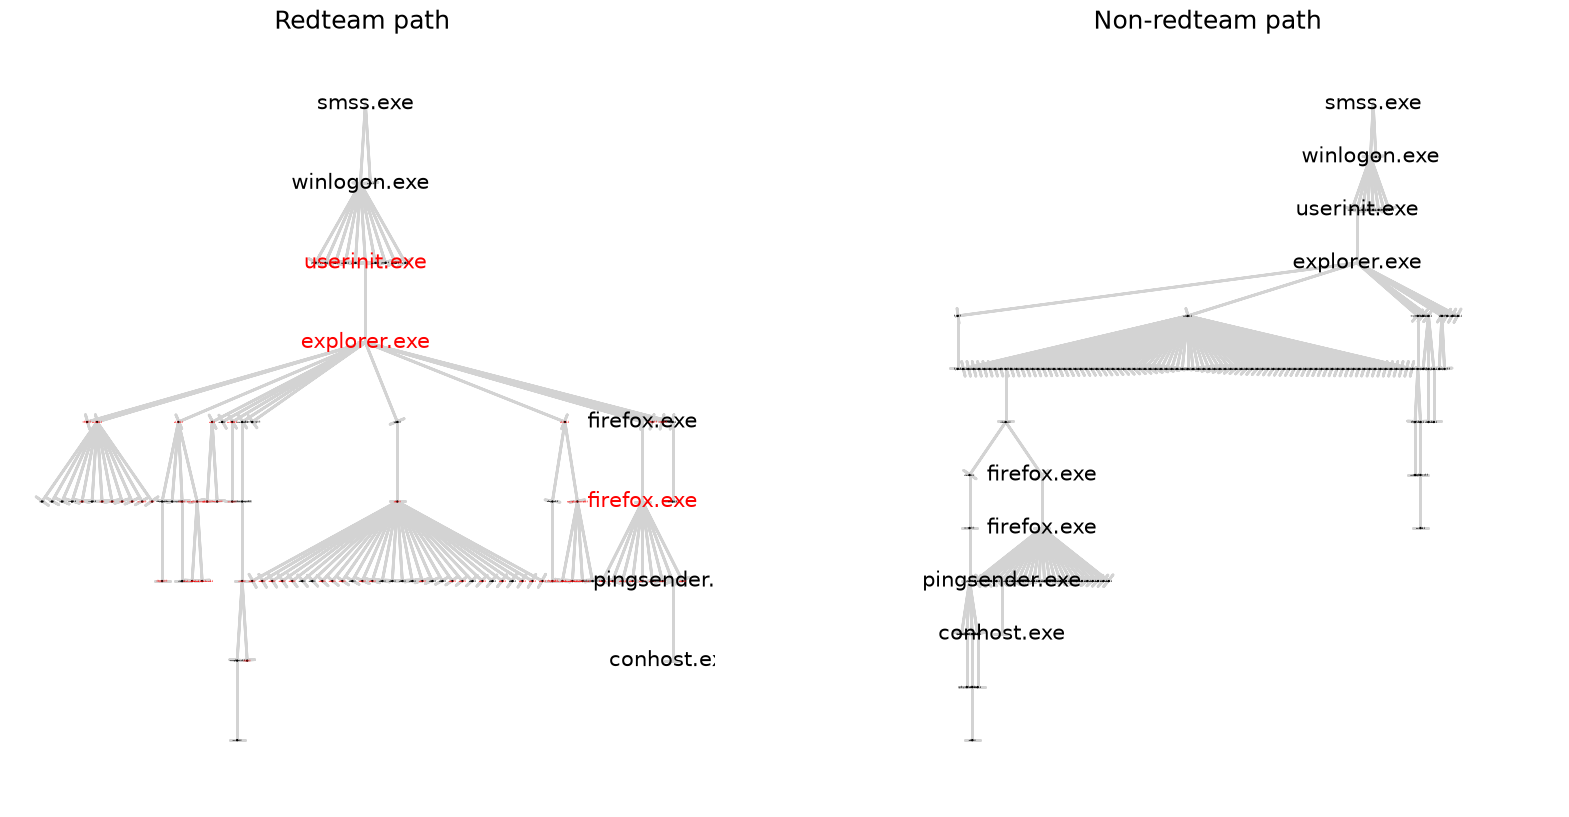

In [15]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

### (1b) redblack weight

A binary score of 1 if the process names coincide AND the labels (here, redteam) are different, 0 otherwise.


In [16]:
## redblack
def _rb(a, b, _process, _label):
    return int(_process[a]==_process[b])*(_label[a]!=_label[b])
weight = partial(_rb, _process=dct_processname, _label=dct_label)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 6.0


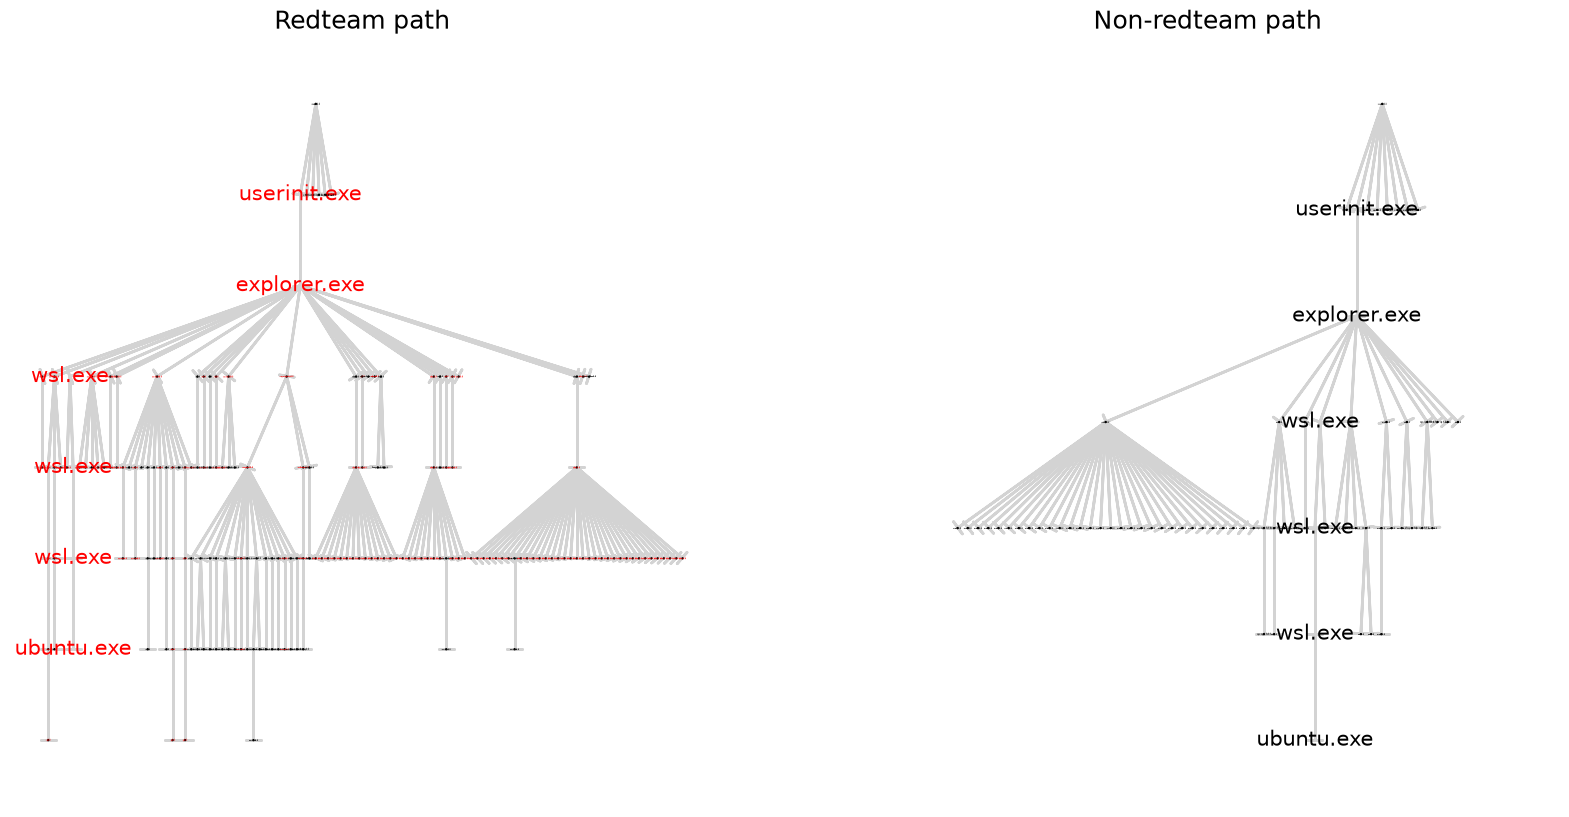

In [17]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

### (1c) inverse fequency weight

A score in (0,1] inversely proportional (on log scale) to the process frequency if the process names coincide, 0 otherwise.


In [18]:
## inverse frequency
proc_counts = Counter([dct_processname.get(v,'') for v in Trees.graph.vs['uid']])
dct_invfreq = {k: float(1/np.log2(v+1)) for k, v in proc_counts.items()} ## max score of 1 when v==1
def _if(a, b, _process, _freq):
    return int(_process[a]==_process[b])*(_freq[_process[a]])
weight = partial(_if, _process=dct_processname, _freq=dct_invfreq)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 1.8869611024856567


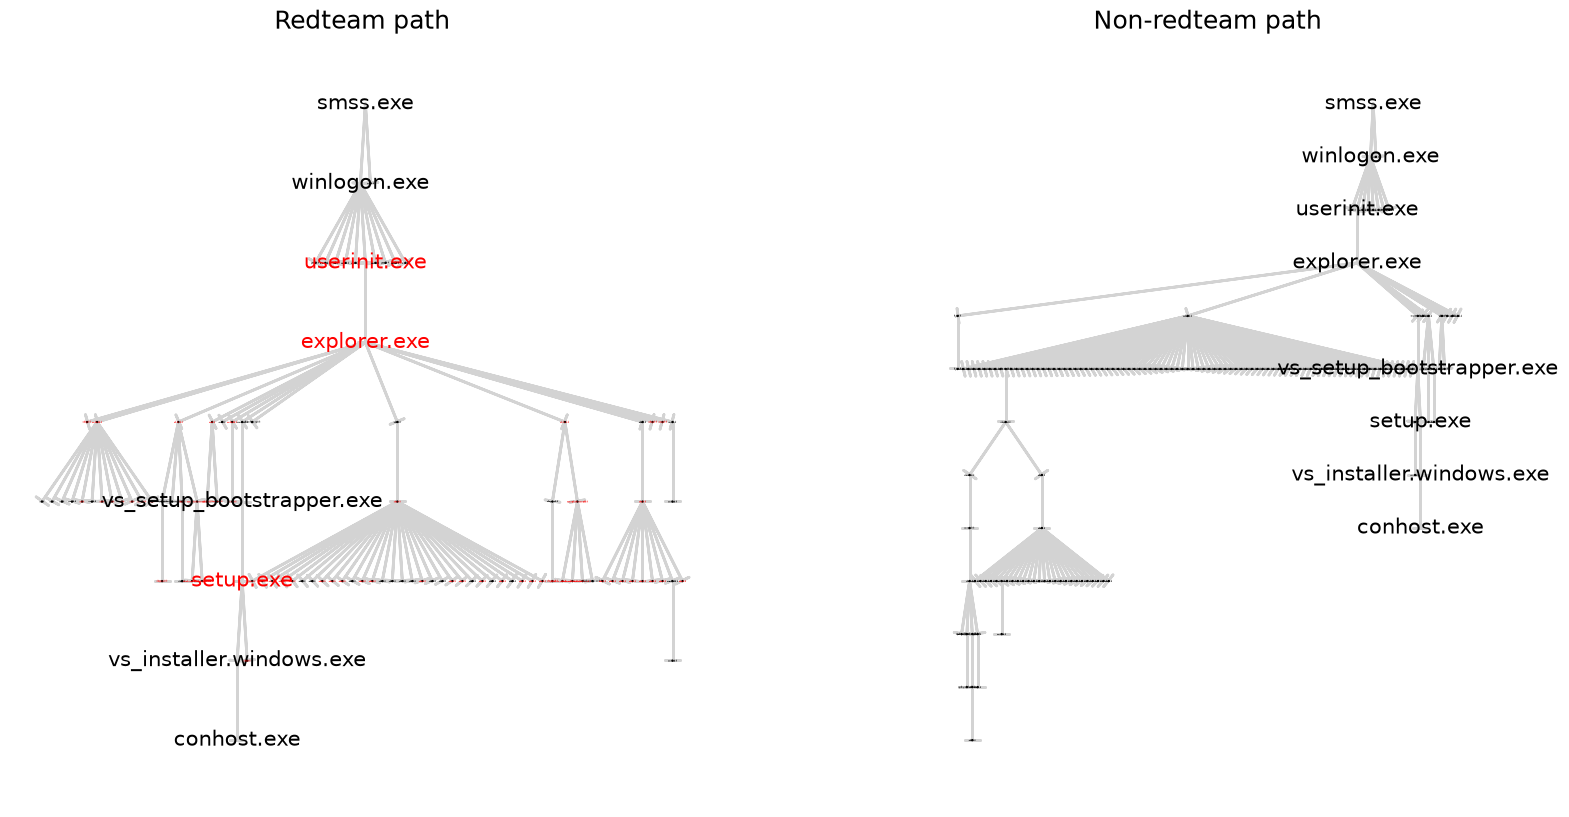

In [19]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

In [20]:
sum([x == 'vs_setup_bootstrapper.exe' for x in Trees.graph.vs['process']])


2

### (1d) embedded weight

A score in (0,1] inversely proportional to the PID's Manhattan distance in embedded space if the process names coincide, 0 otherwise.


In [21]:
# embedded space
with gzip.open('Data/acme4_process_num_features_embedding_ecdf.pkl.gz', 'rb') as fp:
    embedding_ecdf = pickle.load(fp)
dim = len(next(iter(embedding_ecdf.values())))
def _es(a, b, _process, _emb):
    return int(_process[a]==_process[b])*(1-distance.cityblock(_emb[a],_emb[b])/dim)
    #return (1-distance.cityblock(_emb[a],_emb[b])/dim)
weight = partial(_es, _process=dct_processname, _emb=embedding_ecdf)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 7.826830863952637


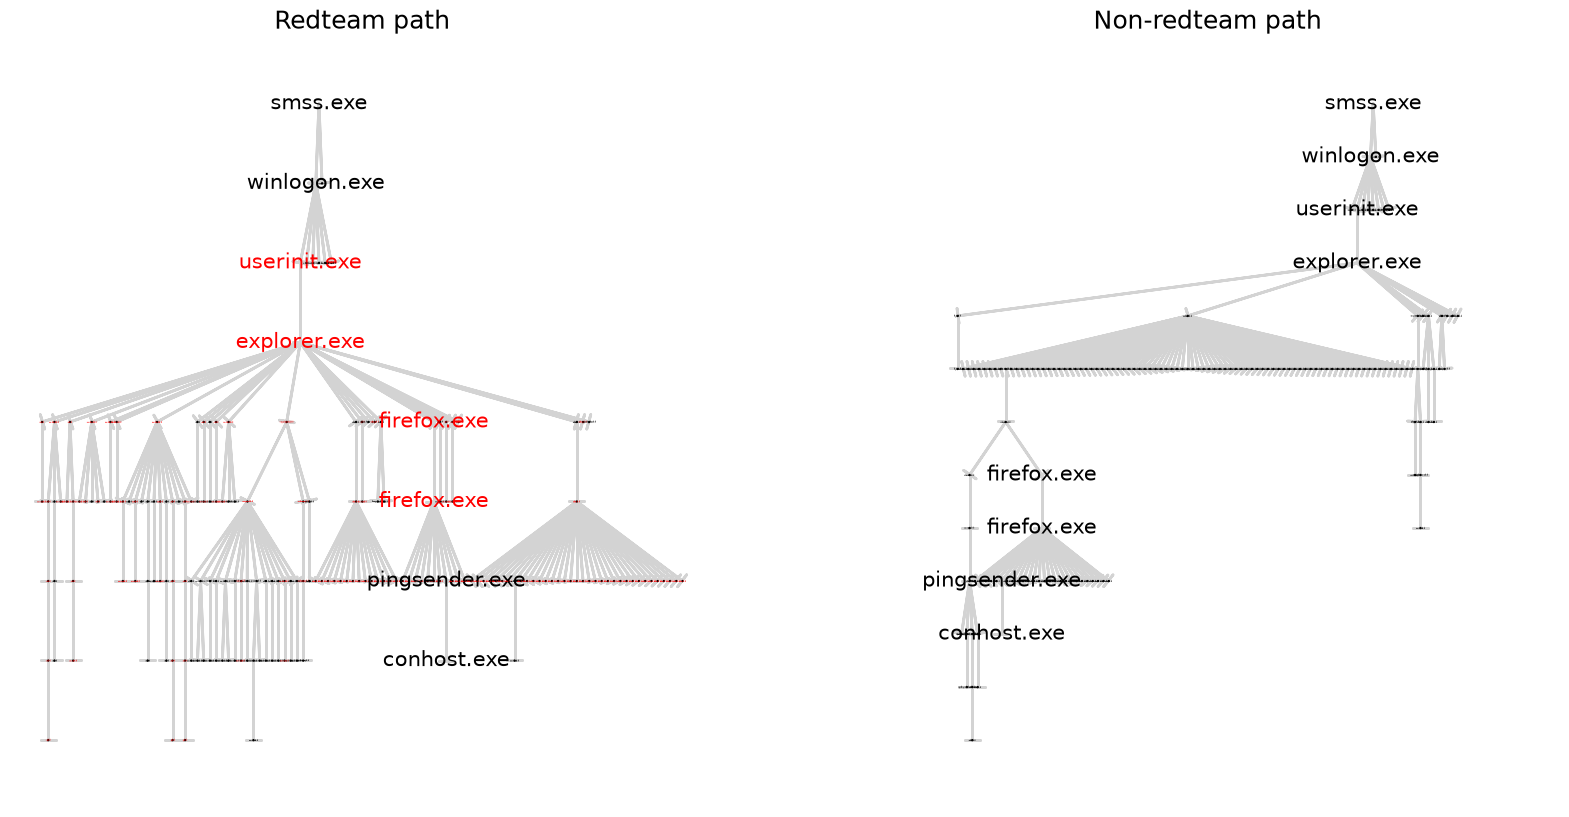

In [22]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

### PLOT in Embed space


In [23]:
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
offx = 3*np.cos(angles)
offy = 3*np.sin(angles)

offx = 2*np.array([1,1,.5,.5,.5,0,0,1.5,-1,0,-.5,-.5,0,.25,-1,-.5])
offy = 3*np.array([1,1,1,1,1,1,1,.5,-1,-1.5,-1,-1,-1,-1,-1,-1])


In [24]:
path = [x[0] for x in match.path_internal]
l = len(path)
s = np.tile(np.arange(l),2)
cl = np.repeat(['red','blue'],l)
l = sg_red.vcount()
path.extend([x[1]+l for x in match.path_internal])


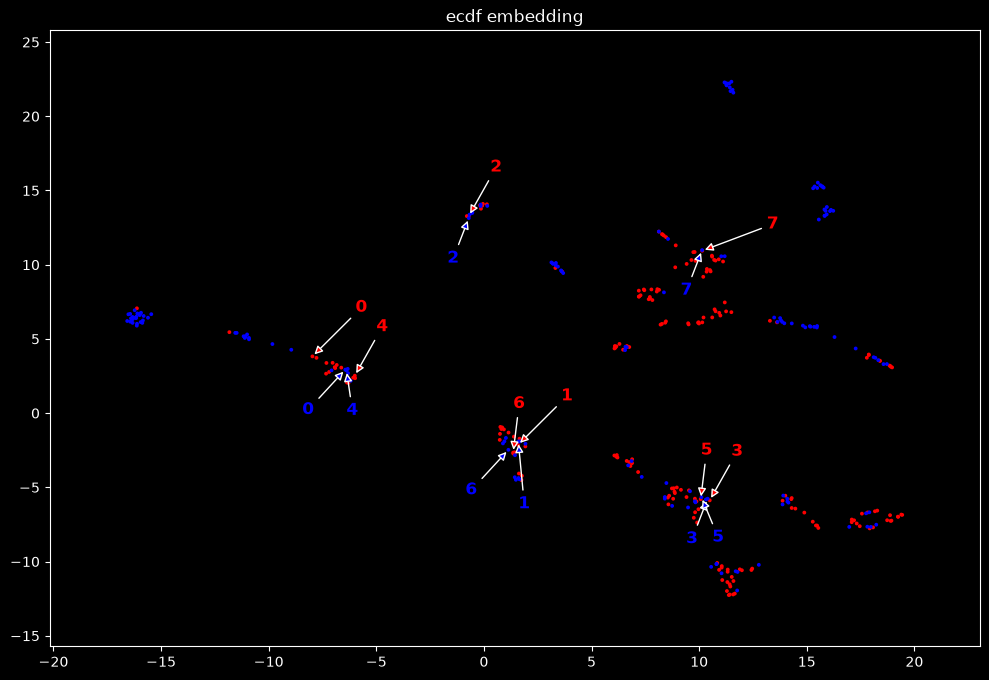

In [25]:
X = [embedding_ecdf[x] for x in sg_red.vs['uid']]
X.extend([embedding_ecdf[x] for x in sg_black.vs['uid']])
c = np.concatenate( [np.repeat('red',sg_red.vcount()), np.repeat('blue',sg_black.vcount())] )
reducer = umap.UMAP(n_neighbors=7, metric='manhattan', min_dist=.25, spread=1.5, n_jobs=1, random_state=123)
embedding = reducer.fit_transform(np.array(X))

with plt.style.context('dark_background'):
    fig, ax = plt.subplots(figsize=(12,8))
    ax.scatter(embedding[:, 0], embedding[:, 1], s=3, c=c );
    ax.set_title('ecdf embedding')
    
    for i in range(len(path)):
        ax.annotate(
            s[i],       # Le texte de l'annotation
            xy=(embedding[path[i], 0], embedding[path[i], 1]),          # Coordonnées (x, y) de la pointe de la flèche
            xytext=(embedding[path[i], 0] + offx[i], embedding[path[i], 1] + offy[i]), # Coordonnées (x, y) du texte (décalé pour laisser de la place)
            arrowprops=dict(
                facecolor=cl[i],          # Couleur de remplissage de la flèche
                arrowstyle="-|>",            # Style de la flèche (ex: "->", "-|>", "fancy")
                lw=1.0                      # Épaisseur de la ligne (line width)
            ),
            fontsize=12,
            color=cl[i],
            fontweight="bold"
        )
    
    ax.margins(.1)

# Experiment #2 - timings

Using the default weights, we compare:
* the "slower" implementation as in experiment #1a
* a faster implementation (due to some pre-processing), and
* a beam search method


### (2a) speedup from experiment (1a)

- we run the matching algorithms 1000 times on the best scoring pair from experiment (1a)


In [26]:
## go back to experiment (1a) - what speedup can we get with the fast method?
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=500) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))
## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## slow
a = time.time()
for _ in range(1000):
    match = nwt.align_trees_algorithm1(TreeData[best_pair[0]], TreeData[best_pair[1]], w=weight)
slow_alg = time.time()-a

## fast
a = time.time()
for _ in range(1000):
    paths, score = fast.predict_encoded(enc[best_pair[0]], enc[best_pair[1]])
fast_alg = time.time()-a

print('time for 1000 runs, slow algorithm:',slow_alg,'fast algorithm:',fast_alg,'speedup:',slow_alg/fast_alg)


time for 1000 runs, slow algorithm: 17.983829259872437 fast algorithm: 0.07250237464904785 speedup: 248.04469297625428


### (2b) fast method - vary the number of trees

By varying the tree sizes, we get different number of tree pairs (still comparing redteam and non-redteam), but we also get trees with large number of paths.
We compute the running time of the matching algorithm as a function of the number of weighted tree pairs we compare, where each tree weight is its number of leaves.


In [27]:
def run_redblack_match_fast(TreeData, _label):
    fast = fm.FastTreePathMatcher()
    fast.fit_encoder(TreeData)
    enc = [fast.encode_tree(t) for t in TreeData]
    best_score = 0
    num_leaves_pairs = 0
    for red in np.where(_label==True)[0]:
        for black in np.where(_label==False)[0]:
            paths, score = fast.predict_encoded(enc[red], enc[black])
            num_leaves_pairs += (_leaves[red]*_leaves[black])
            if score > best_score:
                best_score = score
    return best_score, num_leaves_pairs
        


In [28]:
## extract the subtrees
BS = []
min_layers = 7

for nn in [100,500,1000,2500,5000, 10000]:
    _df = df_trees[ (df_trees.layers>=min_layers) & (df_trees.nodes<=nn) ]
    _trees = _df.tree.tolist()
    _roots = _df.root.tolist()
    _leaves = _df.leaves.tolist()
    TreeData_label = np.array(_df.redteam>0)
    num_tree_pairs = ( sum(TreeData_label==False) * sum(TreeData_label) )
    
    ## faster implementation
    a = time.time()
    TreeData = []
    for (t,r) in zip(_trees,_roots):
        sg = acme_get_bfs_subtree(Trees, t, r) 
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
    fast_preproc = time.time()-a
    
    a = time.time()
    best_score, num_leaves_pairs = run_redblack_match_fast(TreeData, TreeData_label)
    fast_alg = time.time()-a
    BS.append([num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score])
    print(num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score) ## debug


480 300736 3.77624773979187 0.015973329544067383 6.0
4608 65269422 13.318580865859985 0.41285014152526855 9.0
7238 266953316 33.790042877197266 1.5353679656982422 12.0
8580 749315920 65.99680733680725 3.5361549854278564 13.0
8745 844612314 65.68130254745483 3.8762571811676025 13.0
9222 2736928467 124.41938519477844 11.826224565505981 13.0


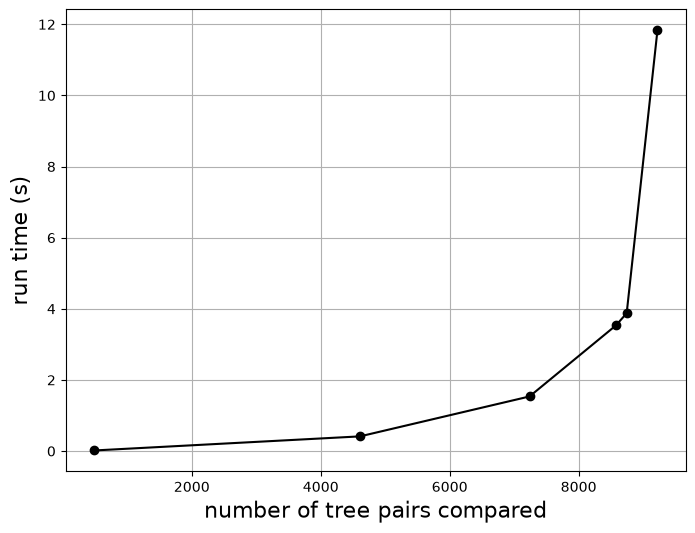

In [29]:
_BS = pd.DataFrame(BS, columns=['pairs','leaves','preproc','time','best'])

plt.figure(figsize=(8,6))
plt.plot(_BS.pairs, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of tree pairs compared', fontsize=16)
plt.ylabel('run time (s)', fontsize=16)
plt.show()


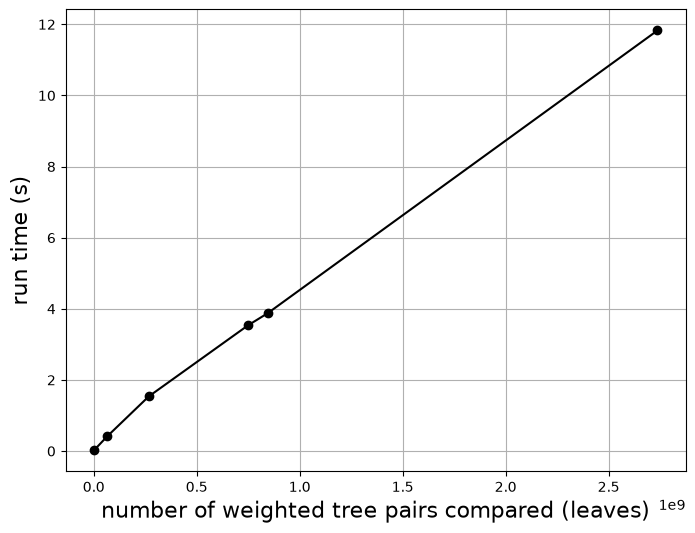

In [30]:
plt.figure(figsize=(8,6))
plt.plot(_BS.leaves, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of weighted tree pairs compared (leaves)', fontsize=16)
plt.ylabel('run time (s)', fontsize=16)
plt.show()


### TODO

- beam search method - compare results with the above default (or do this with DMBD ...)

# Experiment #3 - classification of root processes

We select subtrees with root process from one of the 6 most common ones.

- we first use a random set of trees as templates
- we then use batches and try to use template trees that are ``different'' from the ones already chosen
- we use the fast implementation with default weights


In [31]:
n_class = 6
_df = df_trees[(df_trees.nodes<=5000) & (df_trees.layers>=3)]
common_proc = [x[0] for x in Counter(_df.process).most_common(n_class)]
_df = _df[_df.process.isin(common_proc)]
_df = _df.reset_index()


In [32]:
%%time
Graphs = []
TreeData = []
T = list(_df.tree)
R = list(_df.root)
for i in range(len(T)):
    sg = acme_get_bfs_subtree(Trees, T[i], R[i])
    Graphs.append(sg)
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))

CPU times: user 1min 12s, sys: 39 ms, total: 1min 12s
Wall time: 1min 12s


In [33]:
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [36]:
with open("exp3.pkl", "rb") as fp:
    _results = pickle.load(fp)

### (3a) random set of templates


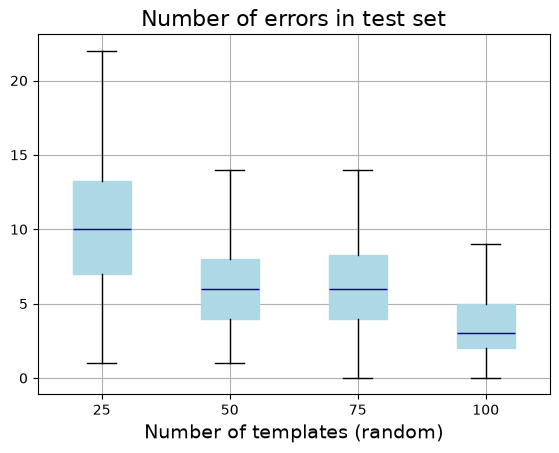

In [37]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['min']==0].boxplot(column='errors', by='templates', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set', fontsize=16)
plt.xlabel('Number of templates (random)', fontsize=14);


### (3b) controlled set of templates

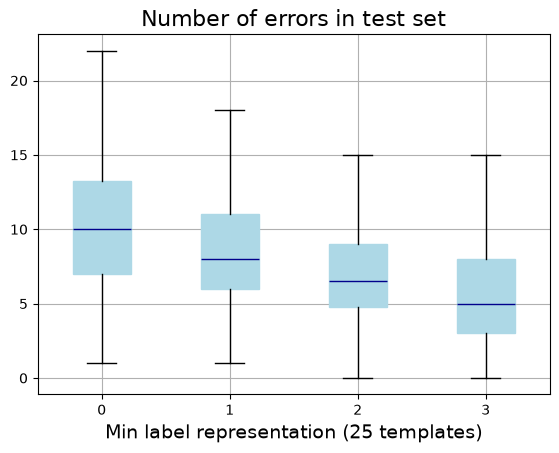

In [38]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['templates']==25].boxplot(column='errors', by='min', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set', fontsize=16)
plt.xlabel('Min label representation (25 templates)', fontsize=14);


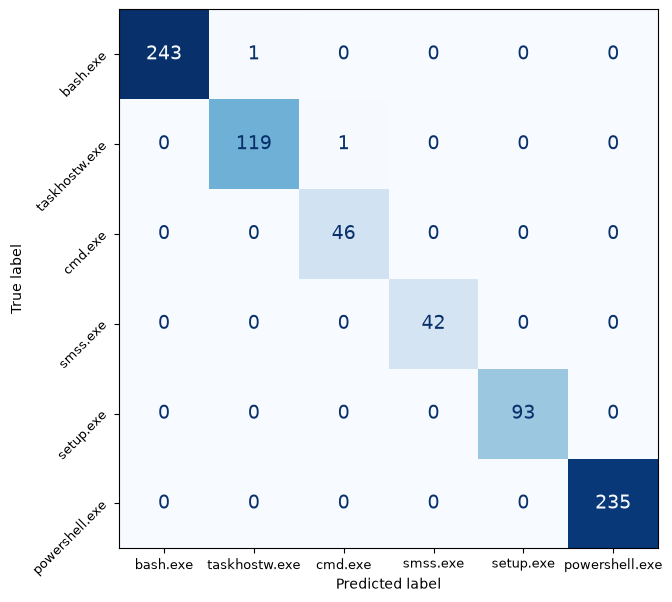

In [39]:
## example of a confusion matrix (last run above)
cm = confusion_matrix(y_test,y_pred)
fig,ax = plt.subplots(figsize=(7,7))
plt.rcParams.update({'font.size': 14}) # Change to your desired size
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                              display_labels=list(label_map.keys())
                             )
disp.plot(colorbar=False, cmap='Blues', ax=ax)
plt.xticks(fontsize=9)
plt.yticks(rotation=45, fontsize=9)
plt.show()


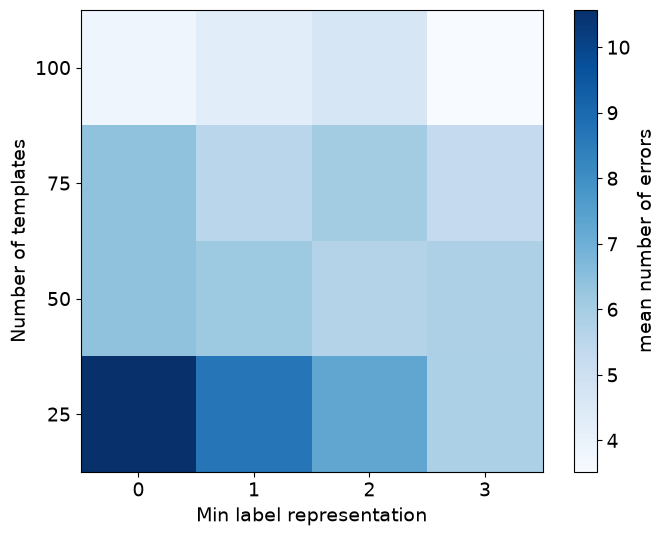

In [40]:
grille_intensite = np.array(_results.groupby(by=['templates','min']).mean(['errors'])).reshape(4,4)
plt.figure(figsize=(8, 6))

# imshow colle parfaitement les carrés par défaut
im = plt.imshow(grille_intensite, cmap='Blues', origin='lower')

# 2. Configuration des axes (optionnel)
plt.yticks(range(4), [25,50,75,100])
plt.xticks(range(4), [0,1,2,3])

plt.colorbar(im, label='mean number of errors')
plt.xlabel('Min label representation', fontsize=14)
plt.ylabel('Number of templates', fontsize=14)
plt.show()

# Experiment #4 - Embedding/Clustering

* We use the same data as in the previous experiment (subtrees with root process from a list of common ones).
* We use 100 random template trees
* For every other tree, we build a vector (embedding) from its matching similarty score using the embedded weights (experiment #1d, ecdf embedding of the pids)


In [41]:
is_template = generate_bool_vector(n_templates, _df.shape[0]-n_templates)
templates = np.where(is_template==True)[0].tolist()
others = np.where(is_template==False)[0].tolist()
Score = np.zeros(shape=(len(templates), len(others)))

## embedding weights
dim = len(next(iter(embedding_ecdf.values())))
def _es(a, b, _process, _emb):
    return int(_process[a]==_process[b])*(1-distance.cityblock(_emb[a],_emb[b])/dim)
    #return (1-distance.cityblock(_emb[a],_emb[b])/dim)
weight = partial(_es, _process=dct_processname, _emb=embedding_ecdf)

## preprocessing
TreeData = []
T = list(_df.tree)
R = list(_df.root)
for i in range(len(T)):
    sg = acme_get_bfs_subtree(Trees, T[i], R[i])
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid')) ## need 'uid' in weight function

## matching algorithm
for i in range(len(templates)):
    for j in range(len(others)):
        match = nwt.align_trees_algorithm1(TreeData[templates[i]], TreeData[others[j]], w=weight)
        Score[i,j] = match.score


In [42]:
## ground truth
GT = []
for i in others:
    v = Trees.subgraph(T[i]).vs[R[i]]
    GT.append(v['process'])
GroundTruth = np.array(GT)


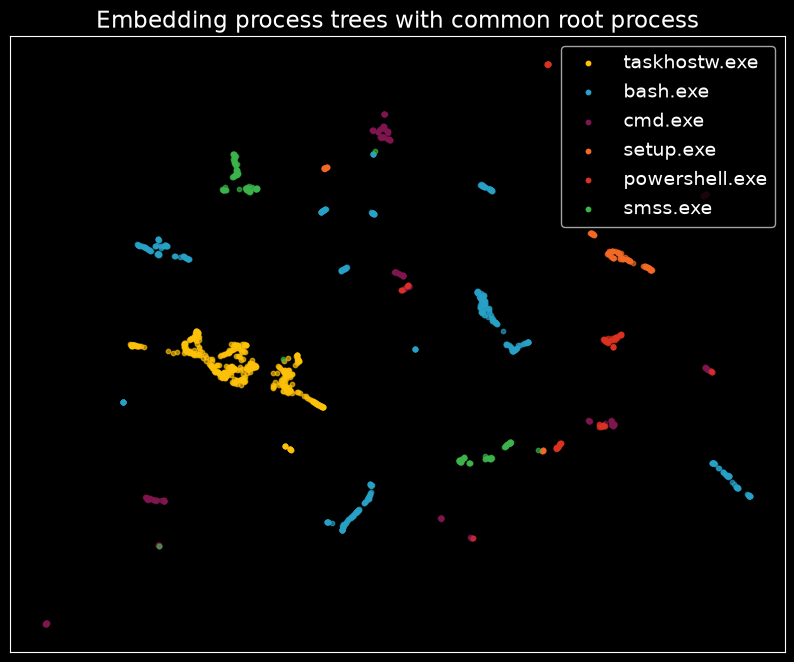

In [43]:
## Embedding
scaler = StandardScaler()
X = scaler.fit_transform( (Score).T )

## 2D mapping
reducer = umap.UMAP(n_neighbors=11, metric='manhattan', init='random', random_state=123, n_jobs=1)
embedding = reducer.fit_transform(X)

# Plot - color w.r.t. GT
with plt.style.context('dark_background'):
    plt.figure(figsize=(10,8))
    _dct = {v:k for k,v in enumerate(set(GT))}
    colors = ['#FFC20A','#28A1C7','#801650','#F46A25','#DC3220','#3cb44b']    
    for c, l in enumerate(_dct):
        plt.scatter(embedding[GroundTruth==l, 0], embedding[GroundTruth==l, 1], s=10, c=colors[c], label=l, alpha=.65)
    plt.title('Embedding process trees with common root process')
    leg = plt.legend()
    for handle in leg.legend_handles:
        handle.set_alpha(1.0)
    plt.tick_params(axis='both', which='both', bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
    plt.show()

### A few quick clustering results from the above

* HDBSCAN
* ECG on KNN graph


In [44]:
## HDBSCAN default
clusterer = HDBSCAN(copy=False)
labels = clusterer.fit_predict(X)
b = (labels>=0)
print('refuse to cluster:',sum(labels==-1),'; number of clusters:',max(labels)+1,'; AMI on clustered points:',AMI(GroundTruth[b], labels[b]))

## HDBSCAN better 
clusterer = HDBSCAN(copy=False, min_cluster_size=25, metric='manhattan', min_samples=1)
labels = clusterer.fit_predict(X)
b = (labels>=0)
print('refuse to cluster:',sum(labels==-1),'; number of clusters:',max(labels)+1,'; AMI on clustered points:',AMI(GroundTruth[b], labels[b]))


refuse to cluster: 505 ; number of clusters: 73 ; AMI on clustered points: 0.5474023807552033
refuse to cluster: 115 ; number of clusters: 17 ; AMI on clustered points: 0.7670004989271344


In [45]:
# Knn graph
knn = NearestNeighbors(n_neighbors=11, metric='minkowski', p=2)
knn.fit(X)
K = knn.kneighbors(X)[1]
_dict = {i: row for i, row in enumerate(K)}
G = ig.Graph.ListDict(_dict, )
G = G.simplify()
G.vs['label'] = [str(i) for i in GroundTruth] 

# ECG clusters
np.random.seed(42)
random.seed(42)
GCC = G.community_ecg(ens_size=100, resolution=.01, final='leiden') ## calibrated to get similar number of clusters as HDBSCAN
G.es['W'] = GCC.W
print(GCC.summary())
print('AMI:',AMI(GCC.membership, G.vs['label']))


Clustering with 1560 elements and 16 clusters
AMI: 0.735824847259479


# Experiment #5 - Filepaths


In [46]:
## the table can be found here: https://gdo168.llnl.gov/data/ACME4/stdview-20240819-20240923/
df_files = pd.read_parquet("Data/process_file.parquet", columns=['pid_hash', 'process_name', 'filename'])

### EDA


In [48]:
## all filepaths
print(df_files.shape[0],'filepaths')
## unique filepaths
print(len(set(df_files.filename)),'unique filepaths')

## split, look at first element and drop, save
S = [f.split('\\') for f in df_files.filename]
print('first item:',Counter([s[0] for s in S]))
S = [s[1:] for s in S]
df_files['path'] = S
df_files['length'] = [len(s) for s in S]


9343199 filepaths
2653580 unique filepaths
first item: Counter({'c:': 9340451, '': 2742, 'd:': 3, 'e:': 2, 'f:': 1})


In [49]:
df_files.head()

,pid_hash,process_name,filename,path,length
0,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\windows\system32\samcli.dll,"[windows, system32, samcli.dll]",3
1,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\windows\temp,"[windows, temp]",2
2,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\programdata\wintap\logs\wintap.log,"[programdata, wintap, logs, wintap.log]",4
3,B696A80670588C5193175908523F8068,ntoskrnl.exe,c:\$logfile,[$logfile],1
4,FC2EC18B2ECC85580CFD8287B0A85E5A,mergehelper.exe,c:\program files\dotnet\shared\microsoft.netco...,"[program files, dotnet, shared, microsoft.netc...",6


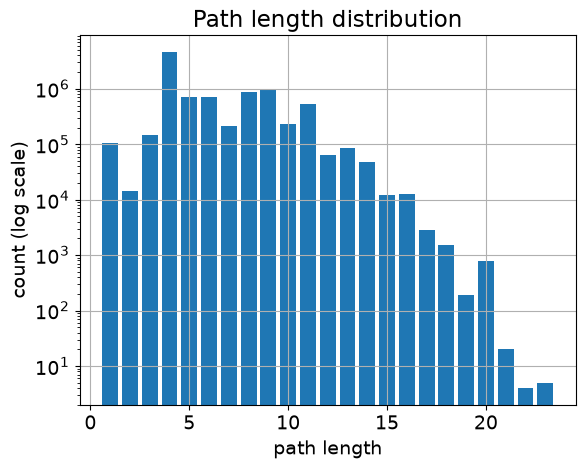

In [50]:
counts = Counter(df_files['length'])
labels, values = zip(*counts.items())
plt.bar(labels, values, )
plt.title("Path length distribution")
plt.xlabel("path length", fontsize=14)
plt.ylabel("count (log scale)", fontsize=14)
plt.yscale('log')
plt.grid()
plt.show()


In [51]:
## drop length 1 paths
df_files = df_files[df_files.length>1]
df_files = df_files.reset_index()

### Examples of matches given a specific path

There are many distinct paths, and many partial matches between paths.

To limit our search, we consider
* paths of a given length only
* 1-off matches only


In [52]:
## limited list
_ = [x for x in df_files[df_files.length==7]['path']]
S = [x for x in _ if ( ( (x[1]=='user1') or (x[1]=='baduser3') ) and (x[6]=='cv_debug.log') )]

## encode all trees
TreeData = []
for s in S:
    sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
    sg.vs['dir'] = s
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## matches
users = np.array([s[1] for s in S ])
for i in np.where(np.array(users)=='user1')[0]:
    for j in np.where(np.array(users)=='baduser3')[0]:
        _, score = fast.predict_encoded(enc[i], enc[j])
        if score == 6:
            print('/'.join(S[i]), '----', '/'.join(S[j]))


users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log
users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log
users/user1/appdata/local/temp/6/cv_debug.log ---- users/baduser3/appdata/local/temp/6/cv_debug.log
users/user1/appdata/local/temp/4/cv_debug.log ---- users/baduser3/appdata/local/temp/4/cv_debug.log
users/user1/appdata/local/temp/4/cv_debug.log ---- users/baduser3/appdata/local/temp/4/cv_debug.log
users/user1/appdata/local/temp/4/cv_debug.log ---- users/baduser3/appdata/local/temp/4/cv_debug.log
users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log
users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log
users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log
users/user1/appdata/local/temp/3/cv_debug.log ---- users/baduser3/appdata/local/temp/3/cv_debug.log


In [54]:
## for quick reference
redteam_dct = process_summary.set_index('pid_hash')['red_team'].to_dict()

## example with baduser3
badfiles = df_files[df_files['pid_hash'] == 'BB8D51837C4CD278B09A83D92341D00B']['path'].tolist()
print(badfiles[0])
print('number of files for redteam PID:',len(badfiles))

## pick non-redteam candidates with similar number of files
_ctr = Counter(df_files['pid_hash'])
candidates = [k for k, c in _ctr.items() if ( (55 <= c <= 65) and (redteam_dct.get(k,-1)==0))]
len(candidates)


['users', 'baduser3', 'documents', 'desktop.ini']
number of files for redteam PID: 59


90

In [55]:
candidate_paths = []
for c in candidates:
    c_files = df_files[df_files['pid_hash'] == c]['path'].tolist()
    candidate_paths.append( (c,c_files) )  

In [56]:
TreeData = []
for s in badfiles:
    sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
    sg.vs['dir'] = s
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))
for (h,c) in candidate_paths:
    for s in c:
        sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
        sg.vs['dir'] = s
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))    
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]
len(enc)


5396

In [57]:
L = []
l = len(badfiles)
lens = [len(x[1]) for x in candidate_paths]
for i in range(len(badfiles)):
    gap = l
    for c in range(len(candidate_paths)):
        max_score = 0
        for j in range(lens[c]):
            _, score = fast.predict_encoded(enc[i], enc[j+gap])
            if score>max_score:
                max_score = score
        gap += lens[c]
        if max_score>=3:
            L.append([i,c,int(max_score),len(badfiles[i])])
df_pid = pd.DataFrame(L, columns=['badfile','candidate','score','max_score'])
df_pid['ratio'] = df_pid['score'] / df_pid['max_score']
df_pid.sort_values(by='score', ascending=False)

,badfile,candidate,score,max_score,ratio
1080,30,12,9,10,0.900000
1096,30,35,9,10,0.900000
1088,30,25,9,10,0.900000
1068,29,87,9,10,0.900000
1715,50,29,9,10,0.900000
...,...,...,...,...,...
2082,58,79,3,9,0.333333
9,0,29,3,4,0.750000
2075,58,67,3,9,0.333333
2077,58,73,3,9,0.333333


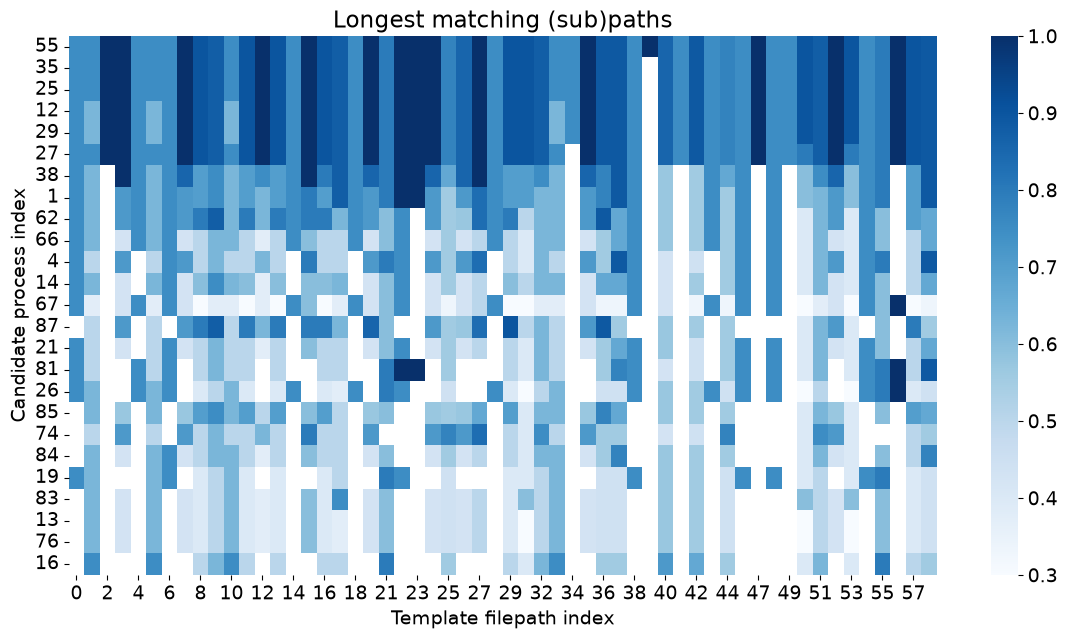

In [58]:
_ = df_pid.groupby(by='candidate').sum().sort_values(by='ratio', ascending=False)
top_candidates = _.nlargest(25,'ratio').index.tolist()
_df = df_pid[df_pid.candidate.isin(top_candidates)]
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Pivot the dataframe so X and Y are your axes, and Intensity is the value
pivot_df = _df.pivot(index="candidate", columns="badfile", values="ratio")
_s = _df.groupby(by='candidate').sum()['ratio'].sort_values(ascending=False).index.tolist()
pivot_df = pivot_df.reindex(_s)
# 2. Create the levelplot/heatmap
plt.figure(figsize=(14, 7))
sns.heatmap(pivot_df, cmap="Blues", annot=False)

# 3. Add labels and display
plt.xlabel("Template filepath index")
plt.ylabel("Candidate process index")
plt.title("Longest matching (sub)paths")
plt.show()

In [67]:
l = [candidates[i] for i in top_candidates[:6]]+['BB8D51837C4CD278B09A83D92341D00B']
process_summary[process_summary['pid_hash'].isin(l)][['pid_hash','red_team','user_name','process_name']]


,pid_hash,red_team,user_name,process_name
1575,BB8D51837C4CD278B09A83D92341D00B,1,ACME\baduser3,explorer.exe
207105,D6F14DA9BF7A140A0C517A8F844EDCA5,0,ACME\user9,explorer.exe
208006,6A7D0BB4BDFE020D8002E7B1DD63119C,0,ACME\user3,explorer.exe
258722,1E573773CE225C0086445E464B30FA83,0,ACME\user1,explorer.exe
558245,64E918B0B8816AA13027EC8F82A80C12,0,ACME\user9,explorer.exe
1246684,E5F28611DE62911DBF2231B3281D8DF8,0,ACME\user3,explorer.exe
1534115,A282FBBB927044F99CA48E7F8445A5A6,0,ACME\user9,explorer.exe


In [77]:
badfiles[39]

['windows', 'system32', 'uiautomationcore.dll']

In [69]:
_.head(10)

,badfile,score,max_score,ratio
candidate,,,,
55,1615,321,368,48.525397
25,1576,318,365,47.525397
35,1576,318,365,47.525397
29,1576,314,365,47.025397
12,1576,314,365,47.025397
27,1542,313,361,46.575397
38,1347,259,344,37.583730
1,1347,243,344,35.376984
62,1324,231,341,33.025794


In [78]:
sum([x[-1:][0]=='uiautomationcore.dll' for x in df_files.path])


371

In [79]:
df_files.shape

(9236939, 6)